<p align="center"><b><font size="5">Predicción de impago de tarjetas de créditos con modelos clásicos de machine learning y redes neuronales</font></b></p>

<p align="center"><b><font size="4">Descripción general:</font></b></p>

La meta del proyecto es predecir el impago de clientes de tarjetas de crédito y crear una aplicación a la que se le pueda introducir datos y te de la predicción de impago, por lo que se considera las mejores métricas con los mejores tiempos en el modelo final. 

Se usarán las siguientes ténicas:

- Logistic Regresion.
- Random Forest.
- XGBoost.
- SVC
- Feedforward Neural Network (FNN)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import recall_score, precision_score, accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score
import joblib
import torch
import torch.nn as nn
import torch.optim as optim

<p align="center"><b><font size="4">Descarga y exploración del Dataset</font></b></p>

Se descarga el dataset y se explora: valores faltantes, duplicados, distribución y sus principlales características.

In [3]:
df = pd.read_csv("default-of-credit-card-clients.csv", header=None)

In [4]:
df.shape

(30002, 25)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30002 entries, 0 to 30001
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       30001 non-null  object
 1   1       30002 non-null  object
 2   2       30002 non-null  object
 3   3       30002 non-null  object
 4   4       30002 non-null  object
 5   5       30002 non-null  object
 6   6       30002 non-null  object
 7   7       30002 non-null  object
 8   8       30002 non-null  object
 9   9       30002 non-null  object
 10  10      30002 non-null  object
 11  11      30002 non-null  object
 12  12      30002 non-null  object
 13  13      30002 non-null  object
 14  14      30002 non-null  object
 15  15      30002 non-null  object
 16  16      30002 non-null  object
 17  17      30002 non-null  object
 18  18      30002 non-null  object
 19  19      30002 non-null  object
 20  20      30002 non-null  object
 21  21      30002 non-null  object
 22  22      30002 non-null

In [6]:
df.isna().sum()

0     1
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
dtype: int64

In [7]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,NaN,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
1,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
2,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
3,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
4,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [8]:
df.duplicated().sum()

np.int64(0)

El data no contiene valores nulos ni duplicados. El nombre de las columnas no están bien dispuestas y el tipo de datos es objeto, por lo que se ordenan los encabezados, se cambia el tipo de datos y se prescinde de columnas innecesarias. 

In [9]:
df.columns = df.iloc[1]
df = df.drop([0, 1]).reset_index(drop=True)
df = df.apply(pd.to_numeric, errors='coerce')
df = df.drop('ID', axis=1)

In [10]:
df.head()

1,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Se remapean las clases binarias a 0 y 1 y se hace one hot encoding sobre columnas categóricas. Se verifica la distribución del target y se separa de las variables independientes. 

In [11]:
df['default payment next month'].value_counts(normalize=True)* 100

default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

In [12]:
df['SEX'] = df['SEX'].map({1:0, 2:1})
categoricas = ['EDUCATION','MARRIAGE']
df_dummies = pd.get_dummies(df, columns=categoricas, drop_first=True, dtype=int)
x = df_dummies.drop('default payment next month', axis=1)
y= df_dummies['default payment next month']

Se identifican y manejan los valores atípicos.

In [13]:
columnas = x.columns
for i in columnas:
    Q1 = x[i].quantile(0.25)
    Q3 = x[i].quantile(0.75)
    IQR = Q3-Q1

    lower = Q1-1.5 * IQR
    upper = Q1+1.5 * IQR

    valor_atipico = x[i][(x[i]<lower) | (x[i]>upper)]
    print(f'{i}, {valor_atipico.count()}')

LIMIT_BAL, 3805
SEX, 0
AGE, 3598
PAY_0, 6818
PAY_2, 4438
PAY_3, 4213
PAY_4, 3510
PAY_5, 2968
PAY_6, 3079
BILL_AMT1, 4985
BILL_AMT2, 5014
BILL_AMT3, 5082
BILL_AMT4, 5165
BILL_AMT5, 5312
BILL_AMT6, 5257
PAY_AMT1, 5187
PAY_AMT2, 4948
PAY_AMT3, 4817
PAY_AMT4, 5003
PAY_AMT5, 4965
PAY_AMT6, 4902
EDUCATION_1, 0
EDUCATION_2, 0
EDUCATION_3, 4917
EDUCATION_4, 123
EDUCATION_5, 280
EDUCATION_6, 51
MARRIAGE_1, 0
MARRIAGE_2, 0
MARRIAGE_3, 323


En algunos casos los valores atípicos llegan al 20% de los datos. Se implementará winsorizing en las columnas númericas a un rango de 10%-90% para mantener todos los datos y se probará en entrenamiento un dataset con y sin winsorizing.

In [14]:
cols =['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6' ]

In [15]:
recortados_numpy = x.copy()

for col in cols:
   
    lower = recortados_numpy[col].quantile(0.10)
    uppper = recortados_numpy[col].quantile(0.90)
    
    recortados_numpy[col] = np.where(recortados_numpy[col]< lower, lower,
                             np.where(recortados_numpy[col] > upper, upper, recortados_numpy[col])) 

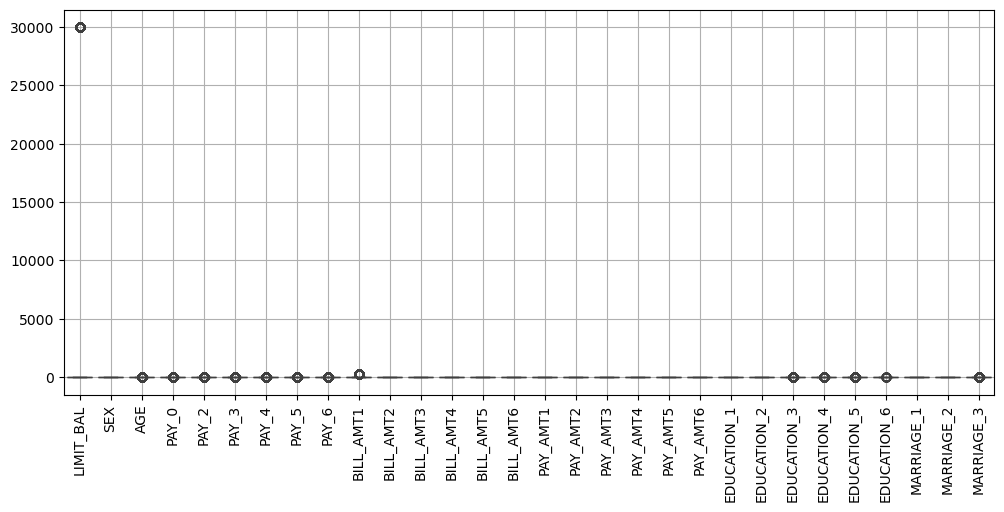

In [16]:
plt.figure(figsize=(12, 5))
sns.boxplot(recortados_numpy)
plt.xticks(rotation = 90)
plt.grid()
plt.show()

In [17]:
x_recortados = pd.DataFrame(recortados_numpy, columns= x.columns, index=x.index)

scaler1 = StandardScaler()
scaler2 = StandardScaler()

x_train_w, x_test_w, y_train_w, y_test_w = train_test_split(x_recortados, y, test_size= 0.2, random_state= 42)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.2, random_state= 42)

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()
x_train_scaled_w = x_train_w.copy()
x_test_scaled_w = x_test_w.copy()

x_train_scaled[cols] = scaler1.fit_transform(x_train[cols])
x_test_scaled[cols] = scaler1.transform(x_test[cols])

x_train_scaled_w[cols] = scaler2.fit_transform(x_train_w[cols])
x_test_scaled_w[cols] = scaler2.transform(x_test_w[cols])

Se inicia el entrenamiento con cuatro modelos ajustándolos a un target desbalanceado y dos conjuntos de dataset. La estadística principal será recall suponiendo que es más costoso no detectar un cliente que cairá en impago que incluir un cliente en impago de forma erronea.

In [18]:
df['default payment next month'].value_counts()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [19]:
scale_pos_weight = 23364/6636

lg = LogisticRegression(max_iter=1000, class_weight='balanced')
forest = RandomForestClassifier(n_estimators = 300, class_weight='balanced', random_state=42)
XGBoost = XGBClassifier(objective="binary:logistic", scale_pos_weight= scale_pos_weight, learning_rate=0.1, random_state=42)
svc = SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced')

In [20]:
def entrenamiento(modelo, x_train, x_test, y_train, y_test, nombre):
    modelo.fit(x_train, y_train)
    y_pred = modelo.predict(x_test)
    
    recall=recall_score(y_test, y_pred) 
    precision=precision_score(y_test, y_pred) 
    accuracy=accuracy_score(y_test, y_pred) 
    f1=f1_score(y_test, y_pred) 
    roc=roc_auc_score(y_test, y_pred)

    diccionario= {'Modelo': nombre,
                 'recall': recall,
                 'presición': precision,
                 'accuracy': accuracy,
                 'F1': f1,
                 'Roc': roc}
    
    return  diccionario

In [21]:
modelo_logistic =  entrenamiento(lg, x_train_scaled, x_test_scaled, y_train, y_test, 'Logistic')
modelo_forest = entrenamiento(forest, x_train_scaled, x_test_scaled, y_train, y_test, 'Forest')
modelo_XGBoost = entrenamiento(XGBoost, x_train_scaled, x_test_scaled, y_train, y_test, 'XGBoost')
modelo_svc = entrenamiento(svc, x_train_scaled, x_test_scaled, y_train, y_test, 'SVC')

In [22]:
modelo_logistic_w =  entrenamiento(lg, x_train_scaled_w, x_test_scaled_w, y_train_w, y_test_w, 'Logistic_w')
modelo_forest_w = entrenamiento(forest, x_train_scaled_w, x_test_scaled_w, y_train_w, y_test_w, 'Forest_w')
modelo_XGBoost_w = entrenamiento(XGBoost, x_train_scaled_w, x_test_scaled_w, y_train_w, y_test_w, 'XGBoost_w')
modelo_svc_w = entrenamiento(svc, x_train_scaled_w, x_test_scaled_w, y_train_w, y_test_w, 'SVC_w')

In [23]:
data = [modelo_logistic, modelo_forest, modelo_XGBoost, modelo_svc, modelo_logistic_w, 
        modelo_forest_w, modelo_XGBoost_w, modelo_svc_w]

resultados_df = pd.DataFrame(data) 
resultados_df

,Modelo,recall,presición,accuracy,F1,Roc
0,Logistic,0.650419,0.379724,0.691000,0.479506,0.676394
1,Forest,0.342727,0.655022,0.816667,0.450000,0.646081
2,XGBoost,0.616908,0.462593,0.759333,0.528721,0.708070
3,SVC,0.583397,0.482368,0.771833,0.528094,0.704009
4,Logistic_w,0.589490,0.445853,0.749833,0.507707,0.692121
5,Forest_w,0.511805,0.474241,0.769000,0.492308,0.676427
6,XGBoost_w,0.594059,0.468750,0.763833,0.524017,0.702726
7,SVC_w,0.604722,0.467885,0.763000,0.527575,0.706031


<p align="center"><b><font size="4">Hasta el momento se puede concluir:</font></b></p>

- Logistic Regression fue el mejor modelo con un recall de **0.65**, pero con la peor precisión **0.38**.
- Aplicar winsorizing no mejoró el modelo.
- Considerando el Roc todos los modelos están por encima de sólo adivinar, pero ninguno sobrepasa el **0.71**.

Se vuelve a repetir el entrenamiento equilibrando el target artificialmente con SMOTE

In [24]:
x_smote, y_smote = SMOTE().fit_resample(x, y)
x_train, x_test, y_train, y_test = train_test_split(x_smote, y_smote, test_size= 0.2, random_state= 42)

scaler3 = StandardScaler()

x_train_smote = x_train.copy()
x_test_smote = x_test.copy()

x_train_smote[cols] = scaler3.fit_transform(x_train[cols])
x_test_smote[cols] = scaler3.transform(x_test[cols])

Se definen los parámetros de los mismos modelos para que manejen clases balanceadas.

In [25]:
lg_s = LogisticRegression(max_iter=1000)
forest_s = RandomForestClassifier(n_estimators = 300, random_state=42)
XGBoost_s = XGBClassifier(objective="binary:logistic", learning_rate=0.1, random_state=42)
svc_s = SVC(kernel='rbf', C=1, gamma='scale')

In [26]:
modelo_logistic_s =  entrenamiento(lg_s, x_train_smote, x_test_smote, y_train, y_test, 'Logistic_s')
modelo_forest_s = entrenamiento(forest_s, x_train_smote, x_test_smote, y_train, y_test, 'Forest_s')
modelo_XGBoost_s = entrenamiento(XGBoost_s, x_train_smote, x_test_smote, y_train, y_test, 'XGBoost_s')
modelo_svc_s = entrenamiento(svc_s, x_train_smote, x_test_smote, y_train, y_test, 'SVC_s')

In [27]:
data2 = [modelo_logistic_s, modelo_forest_s, modelo_XGBoost_s, modelo_svc_s]

resultados_smote = pd.DataFrame(data2) 
resultados_smote

,Modelo,recall,presición,accuracy,F1,Roc
0,Logistic_s,0.711021,0.918598,0.823668,0.801589,0.823885
1,Forest_s,0.833618,0.899102,0.869784,0.865122,0.869854
2,XGBoost_s,0.779368,0.913163,0.852343,0.840977,0.852484
3,SVC_s,0.736437,0.896050,0.825166,0.808441,0.825337


Random Forest fue el mejor modelo con 0.83 de recall. Se prueba reducir el número de columnas, sin afectar las métricas, verificando las columnas más importantes. 

In [28]:
random_forest = RandomForestClassifier(n_estimators = 300, random_state=42)

random_forest.fit(x_train_smote, y_train)
importancia = random_forest.feature_importances_

df_importancia = pd.Series(importancia, index=x.columns).sort_values(ascending=False)
df_importancia

PAY_0          0.073431
MARRIAGE_1     0.055956
PAY_2          0.051267
BILL_AMT1      0.047628
LIMIT_BAL      0.047619
PAY_AMT1       0.045383
AGE            0.043803
MARRIAGE_2     0.042507
PAY_AMT2       0.041048
BILL_AMT2      0.040164
PAY_AMT3       0.038132
BILL_AMT3      0.037697
BILL_AMT4      0.036883
PAY_AMT6       0.035516
BILL_AMT5      0.035506
PAY_AMT4       0.035429
BILL_AMT6      0.035257
EDUCATION_2    0.034741
PAY_AMT5       0.033688
PAY_3          0.032083
EDUCATION_3    0.030050
EDUCATION_1    0.028319
SEX            0.025166
PAY_4          0.022799
PAY_5          0.020777
PAY_6          0.017946
MARRIAGE_3     0.004458
EDUCATION_5    0.004444
EDUCATION_4    0.001604
EDUCATION_6    0.000700
dtype: float64

In [29]:
def forest_clasificacion(model, x_train, x_test, y_train, y_test):
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    recall = recall_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    
    return model, recall, cm

In [30]:
columnas = ['PAY_0', 'MARRIAGE_1', 'PAY_2', 'LIMIT_BAL', 'BILL_AMT1', 'PAY_AMT1', 'AGE', 'MARRIAGE_2', 'PAY_AMT2', 'BILL_AMT2',
'BILL_AMT3', 'PAY_AMT3', 'BILL_AMT5', 'BILL_AMT4', 'BILL_AMT6', 'PAY_AMT4', 'PAY_AMT6', 'EDUCATION_2', 'PAY_AMT5',
'PAY_3', 'EDUCATION_3', 'EDUCATION_1', 'SEX', 'PAY_4', 'PAY_5', 'PAY_6', 'MARRIAGE_3', 'EDUCATION_5', 'EDUCATION_4', 'EDUCATION_6']    

In [35]:
col_reducidas = ['PAY_0', 'MARRIAGE_1', 'PAY_2', 'LIMIT_BAL', 'BILL_AMT1', 'PAY_AMT1', 'AGE', 'MARRIAGE_2', 'PAY_AMT2', 'BILL_AMT2',
'BILL_AMT3', 'PAY_AMT3', 'BILL_AMT5', 'BILL_AMT4', 'BILL_AMT6', 'PAY_AMT4', 'PAY_AMT6', 'EDUCATION_2', 'PAY_AMT5',
'PAY_3'] 

Sin quitar columnas:

In [39]:
start_time = time.time()
forest_model, recall, cm = forest_clasificacion(random_forest, x_train_smote, x_test_smote, y_train, y_test)
end_time = time.time()
training_time = end_time - start_time
print(f"Tiempo de entrenamiento: {training_time:.2f} segundos")
print(forest_model, recall, cm)

Tiempo de entrenamiento: 76.13 segundos
RandomForestClassifier(n_estimators=300, random_state=42) 0.8336181119179837 [[4226  438]
 [ 779 3903]]


Con 5 columnas menos:

In [34]:
start_time = time.time()
forest_model, recall, cm = forest_clasificacion(random_forest, x_train_smote[col_reducidas], x_test_smote[col_reducidas], y_train, y_test)
end_time = time.time()
training_time = end_time - start_time
print(f"Tiempo de entrenamiento: {training_time:.2f} segundos")
print(forest_model, recall, cm)

Tiempo de entrenamiento: 84.21 segundos
RandomForestClassifier(n_estimators=300, random_state=42) 0.8295600170867151 [[4182  482]
 [ 798 3884]]


Con 10 columnas menos:

In [36]:
start_time = time.time()
forest_model, recall, cm = forest_clasificacion(random_forest, x_train_smote[col_reducidas], x_test_smote[col_reducidas], y_train, y_test)
end_time = time.time()
training_time = end_time - start_time
print(f"Tiempo de entrenamiento: {training_time:.2f} segundos")
print(forest_model, recall, cm)

Tiempo de entrenamiento: 84.68 segundos
RandomForestClassifier(n_estimators=300, random_state=42) 0.8180264844083724 [[4157  507]
 [ 852 3830]]


Reducir el número de columnas no mejoró el tiempo de entrenamiento. Finalmente se aborda el problema de que las columnas 'PAY_0' son categóricas, pero hacer un one-hot-encoding aumenta mucho la dimensionalidad. Por lo tanto se hace un flujo en donde se aplica one-hot-encoding a esas columnas y se aplica PCA a las columnas numéricas, para ver si se mejoran las métricas sin aumentar mucho el tiempo de entrenamiento.

In [37]:
num_cols= ['LIMIT_BAL', 'AGE','BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3','PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

cat_cols= ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5','PAY_6',]

bi_cols= ['SEX','EDUCATION_1', 'EDUCATION_2','EDUCATION_3', 'EDUCATION_4', 'EDUCATION_5', 'EDUCATION_6','MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']


preprocesamiento = ColumnTransformer(transformers=[('num', Pipeline([('scaler', StandardScaler()),
                                                                     ('pca', PCA(n_components=9))]), num_cols),
                                                   ('dummies', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
                                                   ('cat', 'passthrough', bi_cols)])

pipeline= Pipeline(steps=[('preproceso', preprocesamiento)])


x_train, x_test, y_train, y_test = train_test_split(x_smote, y_smote, test_size= 0.2, random_state= 42)

x_traint_pca = pipeline.fit_transform(x_train)
x_test_pca = pipeline.transform(x_test)

pca_model = pipeline.named_steps['preproceso'].named_transformers_['num'].named_steps['pca']
print("Varianza explicada por cada componente:", pca_model.explained_variance_ratio_)
print("Varianza acumulada:", pca_model.explained_variance_ratio_.cumsum())

Varianza explicada por cada componente: [0.43279463 0.12223833 0.07493987 0.06469694 0.06228041 0.05978591
 0.05512859 0.0520203  0.05003126]
Varianza acumulada: [0.43279463 0.55503296 0.62997283 0.69466977 0.75695018 0.81673609
 0.87186468 0.92388499 0.97391625]


In [38]:
start_time = time.time()
forest_model, recall, cm = forest_clasificacion(random_forest, x_traint_pca, x_test_pca, y_train, y_test)
end_time = time.time()
training_time = end_time - start_time
print(f"Tiempo de entrenamiento: {training_time:.2f} segundos")
print(forest_model, recall, cm)

Tiempo de entrenamiento: 64.85 segundos
RandomForestClassifier(n_estimators=300, random_state=42) 0.8109782144382742 [[4236  428]
 [ 885 3797]]


El modelo más rápido fue al que se le aplicó PCA con un tiempo de **64.85**, ganado **11.28** segundos respecto al modelo con mejor recall. El costo en la calidad de las predicciones fue la perdida de **0.023** de recall respecto al modelo que mantenía todas las columnas. Para los propósitos de este proyecto se estima que **11.28** segundos menos de entrenamiento no compensa la perdida de **0.023** en recall, por lo que se considera el modelo random forest con todas las columnas como el mejor modelo hasta el momento. 

<p align="center"><b><font size="4">Predicción con Feedforward Neural Network (FNN) </font></b></p> 

Se preprocesa el dataset: se divide en train y test, se estandariza, se convierte a tensores y se agrupa por bacth.

In [40]:
x = df_dummies.drop('default payment next month', axis=1)
y= df_dummies['default payment next month']

In [41]:
cols =['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6' ]

In [42]:
x_res, y_res = SMOTE().fit_resample(x, y)

x_res = pd.DataFrame(x_res, columns=x.columns)  
y_res = pd.Series(y_res)

x_train, x_test, y_train, y_test = train_test_split(x_res, y_res, test_size = 0.2, random_state=42)

scaler_4 = StandardScaler()

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[cols] = scaler_4.fit_transform(x_train[cols]) 
x_test_scaled[cols] = scaler_4.transform (x_test[cols])

x_train_tensor = torch.tensor(x_train_scaled.values, dtype= torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype= torch.float32).unsqueeze(1)

x_test_tensor = torch.tensor(x_test_scaled.values, dtype= torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype= torch.float32).unsqueeze(1)

In [43]:
train_set = torch.utils.data.TensorDataset(x_train_tensor, y_train_tensor)
test_set = torch.utils.data.TensorDataset(x_test_tensor, y_test_tensor)

train_loader = torch.utils.data.DataLoader(train_set, batch_size = 64, shuffle=True, drop_last=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size = 64, shuffle=False)

Se prepara una red neuronal con 30 dimensiones de entreda, 64 capas ocultas y una capa de salida.

In [44]:
input_dim = 30
hiden_dim = 64
output_dim = 1

class fnn_credito(nn.Module):
    def __init__(self, input_dim, hiden_dim, output_dim):
        super(fnn_credito, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hiden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hiden_dim, hiden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hiden_dim, output_dim)
        )

    def forward(self, x):
        return self.network(x)

In [45]:
modelo_fnn = fnn_credito(input_dim, hiden_dim, output_dim)

In [46]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(modelo_fnn.parameters(), lr = 0.01)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo_fnn.to(device)

fnn_credito(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [47]:
start_time = time.time()
epoch = 100

for i in range(epoch):
    modelo_fnn.train()
    perdida_actual = 0
    correccion_entrenamiento =0
    verdaderos_positivos = 0
    falsos_negativos = 0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
    
        optimizer.zero_grad()
        outputs =  modelo_fnn(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        perdida_actual += loss.item()*inputs.size(0)
        probs = torch.sigmoid(outputs)
        predicted = (probs>= 0.5).float()

        correccion_entrenamiento += (predicted == targets).sum().item()
        verdaderos_positivos += ((predicted == 1) & (targets == 1)).sum().item()
        falsos_negativos += ((predicted == 0) & (targets == 1)).sum().item()

    train_loss =  perdida_actual/len(train_loader.dataset)
    train_accuracy = correccion_entrenamiento/len(train_loader.dataset)
    recall = verdaderos_positivos / (verdaderos_positivos + falsos_negativos + 0.0000001)

    if i % 10 == 0:
        print(f' Ciclo {i}|{epoch} | Pérdidas {train_loss:.4f} | Recall {recall:.4f} | Accuracy {train_accuracy:.4f}')
end_time = time.time()
training_time = end_time - start_time
print(f"Tiempo de entrenamiento: {training_time:.2f} segundos")

 Ciclo 0|100 | Pérdidas 0.4380 | Recall 0.7219 | Accuracy 0.8031
 Ciclo 10|100 | Pérdidas 0.3789 | Recall 0.7287 | Accuracy 0.8271
 Ciclo 20|100 | Pérdidas 0.3757 | Recall 0.7318 | Accuracy 0.8290
 Ciclo 30|100 | Pérdidas 0.3755 | Recall 0.7286 | Accuracy 0.8294
 Ciclo 40|100 | Pérdidas 0.3691 | Recall 0.7346 | Accuracy 0.8330
 Ciclo 50|100 | Pérdidas 0.3713 | Recall 0.7352 | Accuracy 0.8331
 Ciclo 60|100 | Pérdidas 0.3711 | Recall 0.7367 | Accuracy 0.8334
 Ciclo 70|100 | Pérdidas 0.3674 | Recall 0.7409 | Accuracy 0.8343
 Ciclo 80|100 | Pérdidas 0.3654 | Recall 0.7439 | Accuracy 0.8375
 Ciclo 90|100 | Pérdidas 0.3651 | Recall 0.7372 | Accuracy 0.8360
Tiempo de entrenamiento: 408.63 segundos


In [48]:
modelo_fnn.eval()
with torch.no_grad():
    perdida_actual = 0
    correccion_entrenamiento =0
    verdaderos_positivos = 0
    falsos_negativos = 0

    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
    
        outputs =  modelo_fnn(inputs)
        loss = criterion(outputs, targets)

        perdida_actual += loss.item()*inputs.size(0)
        probs = torch.sigmoid(outputs)
        predicted = (probs>= 0.5).float()

        correccion_entrenamiento += (predicted == targets).sum().item()
        verdaderos_positivos += ((predicted == 1) & (targets == 1)).sum().item()
        falsos_negativos += ((predicted == 0) & (targets == 1)).sum().item()

    train_loss =  perdida_actual/len(test_loader.dataset)
    train_accuracy = correccion_entrenamiento/len(test_loader.dataset)
    recall = verdaderos_positivos / (verdaderos_positivos + falsos_negativos + 0.0000001)

    print(f' Pérdidas {train_loss:.4f} | Recall {recall:.4f} | Accuracy {train_accuracy:.4f}')

 Pérdidas 0.3878 | Recall 0.7567 | Accuracy 0.8317


El entrenamieto mostró un perdida estable y un puntaje final de recall en la evalación de **0.76** con un tiempo de entrenamiento de 340 segundos. Por lo tanto el mejor modelo es la versión Random Forest en donde se usaron todas las columnas. Ahora se prueba su desempeño con predicciones en tiempo real en un flujo completo que podrá ser usado en la aplicación.

In [49]:
data = pd.read_csv("default-of-credit-card-clients.csv", header=None)

In [50]:
data.columns = data.iloc[1]
data = data.drop([0, 1]).reset_index(drop=True)
data = data.apply(pd.to_numeric, errors='coerce')
data = data.drop('ID', axis=1)
x = data.drop('default payment next month', axis=1)
y = data['default payment next month']

Se crea un subset del entrenamiento para que el modelo final sea más ligero. Con el motivo de que el modelo se entrene con todas las categorías, se estratifica la columna de EDUCATION, ya que algunas de sus categorías son escasas.

In [51]:
x_subset, _, y_subset, _ = train_test_split(
    x, y,
    train_size=2750,
    stratify=x['EDUCATION'],          
    random_state=42
)

In [52]:
x_smote, y_smote = SMOTE().fit_resample(x_subset, y_subset)
x_train, x_test, y_train, y_test = train_test_split(x_smote, y_smote, test_size=0.2, random_state=22)

In [53]:
num_cols= ['LIMIT_BAL', 'AGE','BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3','PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE']

bi_cols= ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5','PAY_6']

random_forest = RandomForestClassifier(n_estimators = 300, random_state=42)

preprocesamiento = ColumnTransformer(transformers=[('num', StandardScaler(), num_cols),
                                                   ('dummies', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
                                                   ('cat', 'passthrough', bi_cols)])

pipeline= Pipeline(steps=[('preproceso', preprocesamiento),
                         ('modelo', random_forest)])

pipeline.fit(x_train, y_train)

score = pipeline.score(x_test, y_test)
y_pred = pipeline.predict(x_test)
recall = recall_score(y_test, y_pred)
print("Recall:", recall)
print("Accuracy:", score)

Recall: 0.8819277108433735
Accuracy: 0.866822429906542


In [54]:
joblib.dump(pipeline, "m_credito.pkl")

['m_credito.pkl']

In [55]:
modelo_cargado = joblib.load("m_credito.pkl")

In [56]:
start_time = time.time()
predicciones = modelo_cargado.predict(x)
end_time = time.time()
prediction_time = end_time - start_time
print(f'Tiempo de predicción de 30000 datos {prediction_time:.4f}')

Tiempo de predicción de 30000 datos 2.0681


Se usa el dataset completo para verificar el tiempo de predicción, el cual fue de **2.0681** con 30000 datos (**0.0006 por dato**). Con el flujo completo el modelo ganó **0.048** de recall, por lo que se verificará su estabilidad.

In [57]:
recall_scorer = make_scorer(recall_score)

cv_results = cross_validate(pipeline, x_train, y_train,
                            cv=5,
                            scoring={'recall': recall_scorer, 'accuracy': 'accuracy'})

print("Recall por fold:", cv_results['test_recall'])
print("Recall promedio:", cv_results['test_recall'].mean())
print("Accuracy por fold:", cv_results['test_accuracy'])
print("Accuracy promedio:", cv_results['test_accuracy'].mean())

C:\Users\usuario\anaconda3\envs\churn_env\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Recall por fold: [0.84057971 0.82608696 0.82608696 0.80232558 0.82267442]
Recall promedio: 0.8235507246376812
Accuracy por fold: [0.85380117 0.84210526 0.84502924 0.81725146 0.83918129]
Accuracy promedio: 0.8394736842105264


In [58]:
recalls = [0.84057971, 0.82608696, 0.82608696, 0.80232558, 0.82267442]
mean_recall = np.mean(recalls)
std_recall = np.std(recalls)
print('Desviación estandar:', std_recall)

Desviación estandar: 0.01228109113071571


<p align="center"><b><font size="4">Conclusiones:</font></b></p>

- Random Forest fue el mejor modelo con un recall de **0.83** con el target equilibrado con SMOTE, aunque ya con todo el flujo tuvo un promedio cercano al **0.88**. El modelo es estable con una desviación estandar de **0.0122**, alcanzando  un promedio de **0.82** de recall, parecido al modelo original.
- La versión del modelo Random Forest en donde se entrena con datos aplicando PCA obtuvo el mejor tiempo de **68.80** segundos y un recall de **0.81**, la diferencia de 11 segundo no equilibra las peores métricas, por lo que se usará el modelo con las mejores, ya que su tiempo en predicciones fue aceptable.

Se puede acceder a la aplicación desde esta dirección: https://predicci-n-de-impagos-de-tarjetas-de-cr-dito-2osxkhbxby5n5ip4w.streamlit.app/